# EDA – Riesgo de adiciones en contratos SECOP II (muestra Salud)
**Contexto:** la tabla `SECOP II – Contratos Electrónicos` (jbjy-vk9h) quedó truncada en origen
(devuelve 1.000 filas desde el 24-oct-2026). Este EDA se hace con la descarga previa del sector Salud
(`src/ingest.py`, 800.011 contratos firmados desde 2017) y sigue la tabla de 9 revisiones del reporte.

**Entradas.** El mismo cuaderno se ejecuta con dos entradas, según las variables de entorno `EDA_TAG` y `EDA_INPUT`:
`salud` (descarga previa, 800 mil contratos; por defecto) y `snapshot` (instantánea de 1.000 filas de la tabla tal como
está hoy, todos los sectores). Con la instantánea, los umbrales de tamaño mínimo se reducen y los resultados son solo indicativos.

**Objetivo `y`** = 1 si el contrato registró adición en **valor** (tabla Adiciones, tipo "Adicion en el valor")
**o** en **tiempo** (`dias_adicionados > 0`).

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
import os
from pathlib import Path
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import KFold

ROOT = Path("..")
TAG = os.environ.get("EDA_TAG", "salud")
INPUT = os.environ.get("EDA_INPUT", "contratos_salud.csv")
RAW, FIG = ROOT / "data/raw", ROOT / "reports" / ("figures" if TAG == "salud" else f"figures_{TAG}")
FIG.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid", context="notebook")
pd.options.display.float_format = "{:,.3f}".format
num = lambda s: pd.to_numeric(s, errors="coerce")

c = pd.read_csv(RAW / INPUT, low_memory=False)
a = pd.read_csv(RAW / "adiciones_valor.csv")
SMALL = len(c) < 50_000   # con muestras pequeñas se bajan los umbrales mínimos de tamaño
MIN_DEP, MIN_ENT, N_DEC = (15, 5, 5) if SMALL else (500, 200, 10)
print(TAG, INPUT, c.shape, a.shape, "| muestra pequeña:", SMALL)

snapshot contratos_snapshot_20261026_0203Z.csv (1000, 45) (257152, 4) | muestra pequeña: True


## 0. Construcción de la variable objetivo y variables al momento de la firma

In [2]:
c["fecha_firma"] = pd.to_datetime(c.fecha_de_firma, errors="coerce")
c["anio"], c["mes"] = c.fecha_firma.dt.year.astype("Int64"), c.fecha_firma.dt.month.astype("Int64")
c["valor"] = num(c.valor_del_contrato)
dur = c.duraci_n_del_contrato.str.extract(r"(\d+)\s*([A-Za-z])")
mult = {"D": 1, "M": 30, "A": 365, "S": 7, "H": 1 / 24}
c["plazo_dias"] = num(dur[0]) * dur[1].map(mult)
c["saldo_cdp_n"] = num(c.saldo_cdp)

n_adic = a.groupby("id_contrato").size()
c["n_adic_valor"] = c.id_contrato.map(n_adic).fillna(0).astype(int)
c["dias_adic"] = num(c.dias_adicionados).fillna(0)
c["y_valor"] = (c.n_adic_valor > 0).astype(int)
c["y_tiempo"] = (c.dias_adic > 0).astype(int)
c["y"] = (c.y_valor | c.y_tiempo).astype(int)

print("Contratos sin fecha de firma válida:", c.fecha_firma.isna().sum())
print("dias_adicionados > 5 años (posible error de digitación):", (c.dias_adic > 1825).sum())

Contratos sin fecha de firma válida: 8
dias_adicionados > 5 años (posible error de digitación): 0


## 1. Tasa global de adición (balance de clases) y madurez de la muestra

Contratos 2017-2025: 810 | tasa y=18.6% | valor=3.8% | tiempo=15.6%
      contratos     y  valor  tiempo
anio                                
2018         20 0.100  0.100   0.000
2019          6 0.500  0.167   0.333
2020         93 0.344  0.108   0.247
2021         89 0.539  0.101   0.494
2022        102 0.029  0.020   0.010
2023         94 0.043  0.000   0.043
2024        315 0.114  0.019   0.095
2025         91 0.253  0.011   0.242


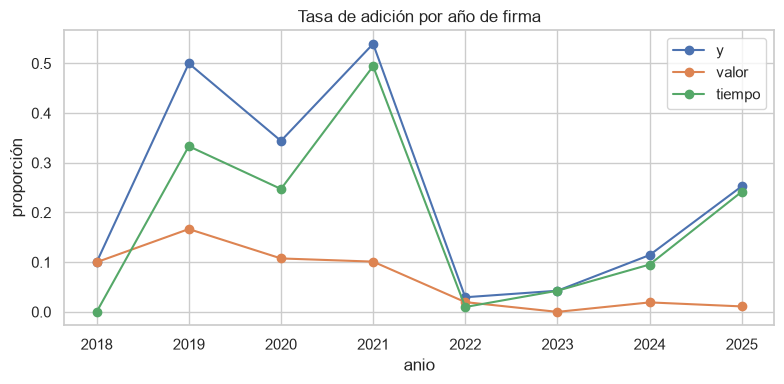

In [3]:
df = c[c.anio.between(2017, 2025)].copy()   # 2026 se excluye: contratos aún sin tiempo de recibir adiciones
print(f"Contratos 2017-2025: {len(df):,} | tasa y={df.y.mean():.1%} | valor={df.y_valor.mean():.1%} | tiempo={df.y_tiempo.mean():.1%}")
by_year = df.groupby("anio").agg(contratos=("y", "size"), y=("y", "mean"), valor=("y_valor", "mean"), tiempo=("y_tiempo", "mean"))
print(by_year.to_string())
ax = by_year[["y", "valor", "tiempo"]].plot(marker="o", figsize=(8, 4), title="Tasa de adición por año de firma")
ax.set_ylabel("proporción"); plt.tight_layout(); plt.savefig(FIG / "01_tasa_por_anio.png", dpi=150); plt.show()

In [4]:
by_state = df.groupby("estado_contrato").agg(contratos=("y", "size"), y=("y", "mean")).sort_values("contratos", ascending=False)
print(by_state.to_string())
print("El estado depende del desenlace ('Modificado' ya implica modificación): no debe usarse para definir la muestra ni como variable.")

                 contratos     y
estado_contrato                 
Cerrado                242 0.045
Modificado             225 0.600
En ejecución           223 0.000
terminado               84 0.036
Aprobado                33 0.030
cedido                   3 0.333
El estado depende del desenlace ('Modificado' ya implica modificación): no debe usarse para definir la muestra ni como variable.


## 2. Nulos / valores no definidos en variables de firma

valor                           0.000
modalidad_de_contratacion       0.000
tipo_de_contrato                0.000
origen_de_los_recursos          0.000
saldo_cdp_n                     0.000
justificacion_modalidad_de      0.000
codigo_proveedor                0.000
es_pyme                         0.000
tipodocproveedor                0.400
fecha_de_inicio_del_contrato    1.900
departamento                    2.200
plazo_dias                      8.100
habilita_pago_adelantado        9.600
condiciones_de_entrega         24.800


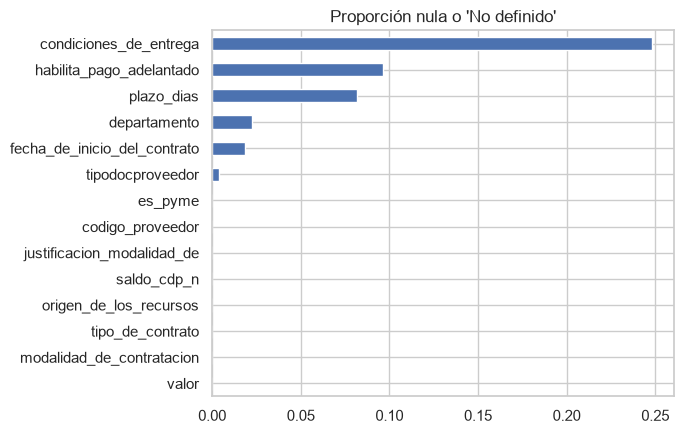

Ofertas, garantías y proveedores (tablas aparte) no se descargaron en esta muestra: ver limitaciones.


In [5]:
firma_vars = ["valor", "plazo_dias", "modalidad_de_contratacion", "tipo_de_contrato", "departamento", "origen_de_los_recursos",
              "condiciones_de_entrega", "tipodocproveedor", "es_pyme", "habilita_pago_adelantado", "codigo_proveedor",
              "fecha_de_inicio_del_contrato", "saldo_cdp_n", "justificacion_modalidad_de"]
undef = lambda s: s.isna() | s.astype(str).str.strip().str.lower().isin(["no definido", "no definida", "sin descripcion", "nan", "no d"])
nul = pd.Series({v: undef(df[v]).mean() for v in firma_vars}).sort_values()
print((nul * 100).round(1).to_string())
nul.plot.barh(figsize=(7, 4.5), title="Proporción nula o 'No definido'"); plt.tight_layout(); plt.savefig(FIG / "02_nulos.png", dpi=150); plt.show()
print("Ofertas, garantías y proveedores (tablas aparte) no se descargaron en esta muestra: ver limitaciones.")

## 3. Variación por departamento

                            contratos     y
departamento                               
No Definido                        18 0.111
Tolima                             15 0.133
Magdalena                          21 0.143
Boyacá                             26 0.154
Antioquia                          55 0.182
Nariño                             16 0.188
Bolívar                            27 0.259
Distrito Capital de Bogotá        338 0.269
                    contratos     y
departamento                       
Risaralda                  20 0.050
Valle del Cauca            86 0.070
Santander                  25 0.080
Cundinamarca               24 0.083
Norte de Santander         19 0.105
Rango de tasa entre departamentos (n>=15): 5.0% - 26.9%


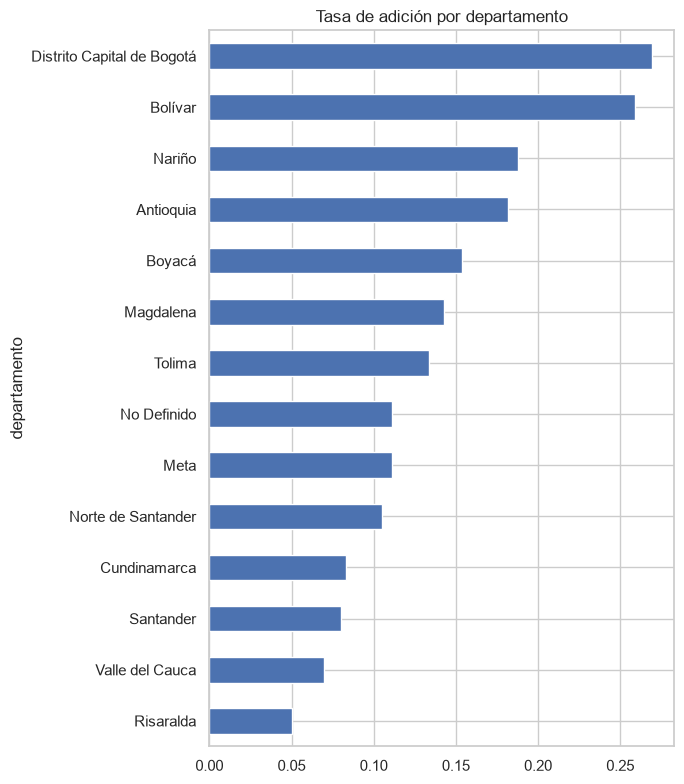

In [6]:
dep = df.groupby("departamento").agg(contratos=("y", "size"), y=("y", "mean")).query("contratos >= @MIN_DEP").sort_values("y")
print(dep.tail(8).to_string()); print(dep.head(5).to_string())
print(f"Rango de tasa entre departamentos (n>={MIN_DEP}): {dep.y.min():.1%} - {dep.y.max():.1%}")
dep.y.plot.barh(figsize=(7, 8), title="Tasa de adición por departamento"); plt.tight_layout(); plt.savefig(FIG / "03_departamento.png", dpi=150); plt.show()

## 4. Modalidad de contratación y tipo de contrato

                                             contratos     y  valor  tiempo
modalidad_de_contratacion                                                  
Contratación directa                               592 0.152  0.032   0.125
Contratación régimen especial                      153 0.268  0.039   0.248
Mínima cuantía                                      32 0.125  0.094   0.031
Contratación Directa (con ofertas)                  12 0.333  0.000   0.333
Selección Abreviada de Menor Cuantía                 7 0.571  0.286   0.286
Selección abreviada subasta inversa                  5 0.400  0.200   0.200
Contratación régimen especial (con ofertas)          4 0.500  0.000   0.500
Concurso de méritos abierto                          3 1.000  0.000   1.000
Licitación pública                                   2 0.500  0.000   0.500
Categorías con < 1.000 contratos: 9 de 9
                            contratos     y
tipo_de_contrato                           
Prestación de servicios           7

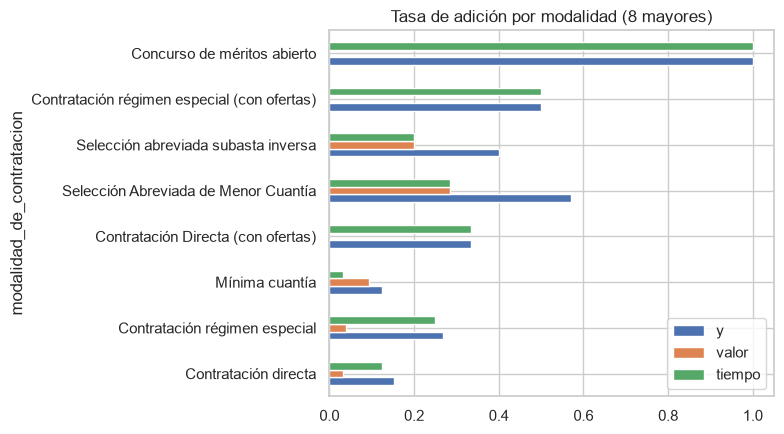

In [7]:
mod = df.groupby("modalidad_de_contratacion").agg(contratos=("y", "size"), y=("y", "mean"), valor=("y_valor", "mean"), tiempo=("y_tiempo", "mean")).sort_values("contratos", ascending=False)
print(mod.to_string())
print("Categorías con < 1.000 contratos:", (mod.contratos < 1000).sum(), "de", len(mod))
tip = df.groupby("tipo_de_contrato").agg(contratos=("y", "size"), y=("y", "mean")).sort_values("contratos", ascending=False).head(10)
print(tip.to_string())
mod.head(8)[["y", "valor", "tiempo"]].plot.barh(figsize=(8, 4.5), title="Tasa de adición por modalidad (8 mayores)")
plt.tight_layout(); plt.savefig(FIG / "04_modalidad.png", dpi=150); plt.show()

## 5. Valor y plazo vs adición

dec_valor
1   0.101
2   0.108
3   0.155
4   0.203
5   0.345


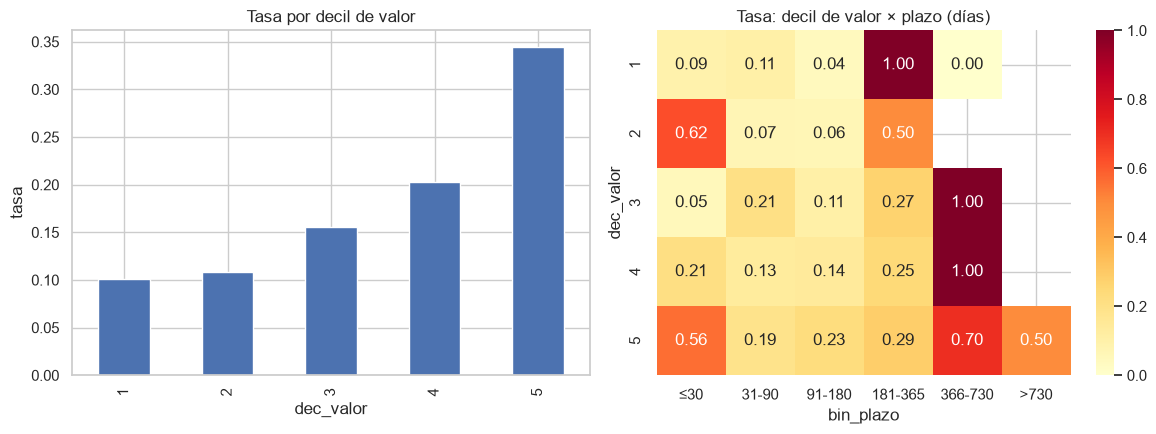

Spearman valor~y: 0.224 | plazo~y: 0.11


In [8]:
d5 = df[(df.valor > 0) & (df.plazo_dias > 0) & (df.plazo_dias <= 3650)].copy()
d5["dec_valor"] = pd.qcut(d5.valor, N_DEC, labels=False, duplicates="drop") + 1
d5["bin_plazo"] = pd.cut(d5.plazo_dias, [0, 30, 90, 180, 365, 730, 3650], labels=["≤30", "31-90", "91-180", "181-365", "366-730", ">730"])
rate_v = d5.groupby("dec_valor").y.mean()
print(rate_v.round(3).to_string())
hm = d5.pivot_table(index="dec_valor", columns="bin_plazo", values="y", aggfunc="mean", observed=True)
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
rate_v.plot.bar(ax=ax[0], title="Tasa por decil de valor"); ax[0].set_ylabel("tasa")
sns.heatmap(hm, annot=True, fmt=".2f", cmap="YlOrRd", ax=ax[1]); ax[1].set_title("Tasa: decil de valor × plazo (días)")
plt.tight_layout(); plt.savefig(FIG / "05_valor_plazo.png", dpi=150); plt.show()
print("Spearman valor~y:", round(d5[["valor", "y"]].corr("spearman").iloc[0, 1], 3), "| plazo~y:", round(d5[["plazo_dias", "y"]].corr("spearman").iloc[0, 1], 3))

## 6. Estacionalidad (mes de firma)

mes            1      2      3      4       5      6      7       8      9      10     11     12
contratos 140.000 77.000 14.000 34.000 100.000 37.000 22.000 140.000 87.000 63.000 78.000 18.000
y           0.143  0.091  0.143  0.618   0.420  0.189  0.182   0.071  0.000  0.286  0.141  0.500


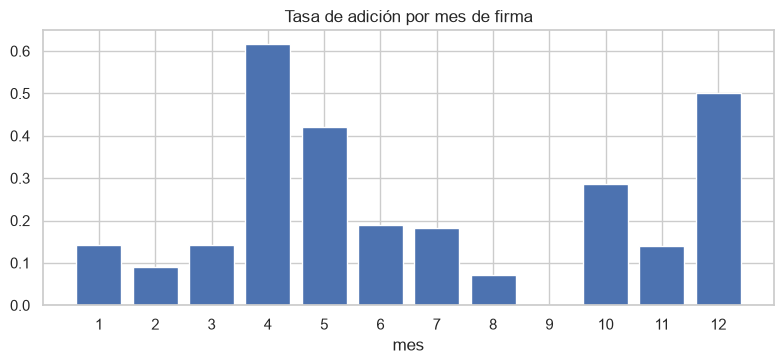

Mes con mayor/menor tasa: 4 (61.8%) / 9 (0.0%)


In [9]:
mes = df.groupby("mes").agg(contratos=("y", "size"), y=("y", "mean"))
print(mes.T.to_string())
fig, ax = plt.subplots(figsize=(8, 3.8)); ax.bar(mes.index, mes.y); ax.set_xticks(range(1, 13)); ax.set_title("Tasa de adición por mes de firma"); ax.set_xlabel("mes")
plt.tight_layout(); plt.savefig(FIG / "06_mes.png", dpi=150); plt.show()
print(f"Mes con mayor/menor tasa: {mes.y.idxmax()} ({mes.y.max():.1%}) / {mes.y.idxmin()} ({mes.y.min():.1%})")

## 7. Concentración por entidad

Entidades: 370. Top 10 concentran 39.7% de los contratos con adición; top 100: 100.0%
                                                                             contratos  adic     y
nombre_entidad                                                                                    
SUBRED INTEGRADA DE SERVICIO DE SALUD CENTRO ORIENTE E.S.E 1                        14    12 0.857
(Secretaría Distrital de Integración Social)                                        17    11 0.647
SUBRED INTEGRADA DE SERVICIOS DE SALUD NORTE E.S.E. (OFICIAL)                       41     6 0.146
SUBRED INTEGRADA DE SERVICIOS DE SALUD SUR E.S.E.**                                 19     6 0.316
SECRETARÍA DISTRITAL DE MOVILIDAD                                                    8     6 0.750
SECRETARIA DISTRITAL DE SEGURIDAD, CONVIVENCIA Y JUSTICIA                            6     5 0.833
INVIAS                                                                              10     4 0.400
SUBRED INTEGRADA DE SER

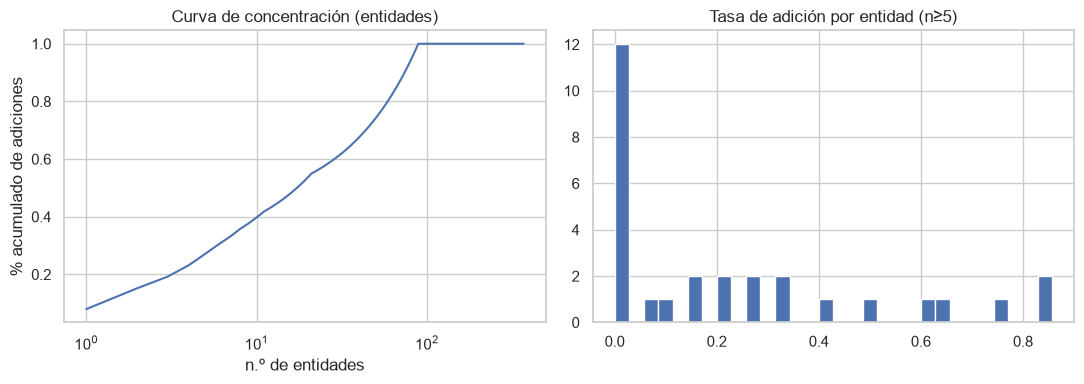

In [10]:
ent = df.groupby("nombre_entidad").agg(contratos=("y", "size"), adic=("y", "sum"), y=("y", "mean")).sort_values("adic", ascending=False)
ent["acum"] = ent.adic.cumsum() / ent.adic.sum()
print(f"Entidades: {len(ent):,}. Top 10 concentran {ent.acum.iloc[min(9, len(ent) - 1)]:.1%} de los contratos con adición; top 100: {ent.acum.iloc[min(99, len(ent) - 1)]:.1%}")
print(ent.head(10)[["contratos", "adic", "y"]].to_string())
big = ent[ent.contratos >= MIN_ENT]
print(f"Entidades con >={MIN_ENT} contratos: {len(big)}. Tasa p10/p50/p90: {big.y.quantile([.1, .5, .9]).round(3).tolist()}")
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(range(1, len(ent) + 1), ent.acum.values); ax[0].set_xscale("log"); ax[0].set_title("Curva de concentración (entidades)")
ax[0].set_xlabel("n.º de entidades"); ax[0].set_ylabel("% acumulado de adiciones")
if len(big): big.y.hist(bins=30, ax=ax[1])
ax[1].set_title(f"Tasa de adición por entidad (n≥{MIN_ENT})")
plt.tight_layout(); plt.savefig(FIG / "07_entidades.png", dpi=150); plt.show()

## 8. Adición en tiempo vs en valor

In [11]:
print(pd.crosstab(df.y_valor, df.y_tiempo, margins=True).to_string())
print("P(valor | tiempo) =", round(df[df.y_tiempo == 1].y_valor.mean(), 3), "| P(tiempo | valor) =", round(df[df.y_valor == 1].y_tiempo.mean(), 3))
pm = df[df.modalidad_de_contratacion.isin(mod.head(6).index)].groupby("modalidad_de_contratacion")[["y_valor", "y_tiempo"]].mean()
print(pm.round(3).to_string())
print(df.groupby("tipo_de_contrato")[["y_valor", "y_tiempo"]].mean().loc[tip.index[:6]].round(3).to_string())

y_tiempo    0    1  All
y_valor                
0         659  120  779
1          25    6   31
All       684  126  810
P(valor | tiempo) = 0.048 | P(tiempo | valor) = 0.194
                                      y_valor  y_tiempo
modalidad_de_contratacion                              
Contratación Directa (con ofertas)      0.000     0.333
Contratación directa                    0.032     0.125
Contratación régimen especial           0.039     0.248
Mínima cuantía                          0.094     0.031
Selección Abreviada de Menor Cuantía    0.286     0.286
Selección abreviada subasta inversa     0.200     0.200
                         y_valor  y_tiempo
tipo_de_contrato                          
Prestación de servicios    0.033     0.146
Decreto 092 de 2017        0.032     0.129
Otro                       0.036     0.393
Suministros                0.067     0.067
Compraventa                0.214     0.143
Obra                       0.000     0.111


## 9. Fuga de información: poder predictivo de una sola variable (AUC)
AUC univariada contra `y`. Numéricas: AUC directa. Categóricas: codificación por la tasa del *fold* de entrenamiento (5-fold).
Valores cercanos a 1 = sospecha de fuga; ~0,5 = sin señal.

                 variable                            momento  auc_univariada
                dias_adic  SOSPECHOSA (posterior a la firma)           0.917
          estado_contrato SOSPECHOSA (depende del desenlace)           0.878
           nombre_entidad                              firma           0.679
                    valor                              firma           0.660
            ultima_act_ts  SOSPECHOSA (posterior a la firma)           0.643
             departamento                              firma           0.589
               plazo_dias                              firma           0.580
              saldo_cdp_n                              firma           0.552
modalidad_de_contratacion                              firma           0.548
         tipodocproveedor                              firma           0.536
                      mes                              firma           0.526
              saldo_vig_n  SOSPECHOSA (posterior a la firma)           0.522

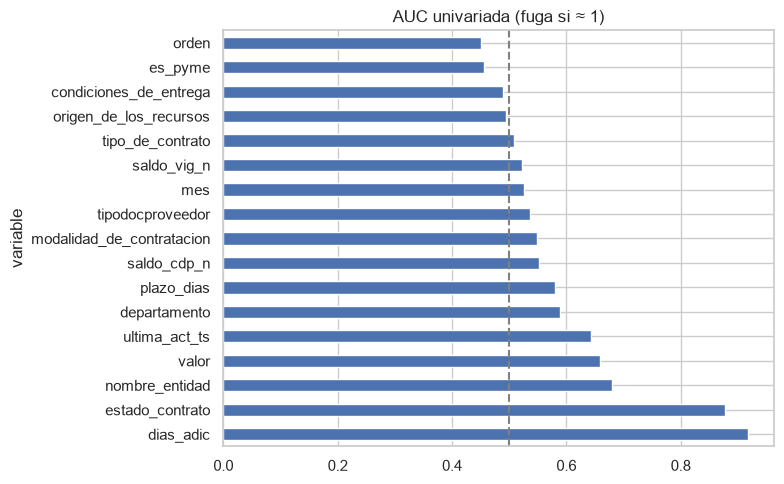

In [12]:
def auc_num(x, y):
    m = x.notna(); s = roc_auc_score(y[m], x[m]); return max(s, 1 - s)

def auc_cat(x, y, k=5):
    x = x.fillna("NA").astype(str).reset_index(drop=True); y = y.reset_index(drop=True); oof = np.zeros(len(x))
    for tr, te in KFold(k, shuffle=True, random_state=0).split(x):
        rate = y.iloc[tr].groupby(x.iloc[tr]).mean()
        oof[te] = x.iloc[te].map(rate).fillna(y.iloc[tr].mean()).values
    return roc_auc_score(y, oof)

df["ultima_act_ts"] = pd.to_datetime(df.ultima_actualizacion, errors="coerce").astype("int64") / 1e9
df.loc[df.ultima_actualizacion.isna(), "ultima_act_ts"] = np.nan
df["saldo_vig_n"] = num(df.saldo_vigencia)
res = []
for v in ["valor", "plazo_dias", "saldo_cdp_n", "mes"]:
    res.append((v, "firma", auc_num(df[v], df.y)))
for v in ["modalidad_de_contratacion", "tipo_de_contrato", "departamento", "nombre_entidad", "origen_de_los_recursos",
          "condiciones_de_entrega", "tipodocproveedor", "es_pyme", "orden"]:
    res.append((v, "firma", auc_cat(df[v], df.y)))
for v in ["saldo_vig_n", "ultima_act_ts", "dias_adic"]:
    res.append((v, "SOSPECHOSA (posterior a la firma)", auc_num(df[v], df.y)))
res.append(("estado_contrato", "SOSPECHOSA (depende del desenlace)", auc_cat(df.estado_contrato, df.y)))
leak = pd.DataFrame(res, columns=["variable", "momento", "auc_univariada"]).sort_values("auc_univariada", ascending=False)
print(leak.round(3).to_string(index=False))
leak.set_index("variable").auc_univariada.plot.barh(figsize=(8, 5), title="AUC univariada (fuga si ≈ 1)"); plt.axvline(0.5, color="gray", ls="--")
plt.tight_layout(); plt.savefig(FIG / "09_fuga_auc.png", dpi=150); plt.show()

In [13]:
print("Valor mediano del contrato según tenga o no adición en valor:")
print(df.groupby("y_valor").valor.median().to_string())

Valor mediano del contrato según tenga o no adición en valor:
y_valor
0   17,500,000.000
1   30,200,000.000
